# M2.8 · 因子拥挤、衰减与容量

> 因子不是永远有效：资金拥挤会让因子变贵、未来收益下降；因子会随时间衰减；因子能承载的资金受流动性和冲击限制。
> 本节研究因子的滚动衰减、拥挤度、估值价差和资金容量。

## 一、核心概念

| 主题 | 含义 | 度量 |
|---|---|---|
| 衰减 | 因子 IC 随时间走弱 | 滚动 IC、滚动 IR |
| 拥挤 | 太多资金涌入，暴露集中、估值变贵 | 拥挤度、估值价差 |
| 容量 | 因子可承载的资金 | 冲击模型反推参与率 |

拥挤因子的典型风险：估值价差收窄、暴露高度集中、近期已大幅上涨，一旦反转回撤剧烈。


## 二、加载数据并计算因子

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2 import barra, crowding
from factor_lab2.combine import cross_zscore
from factor_lab.evaluate import ic_series, fwd_returns
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$high','$low','$volume',
                         '$mkt_cap_ard','$pe_ttm','$pb_lf'],
                 start_time='2018-01-01', freq='day')
cl=raw['$close'].unstack('instrument'); vo=raw['$volume'].unstack('instrument')
mk=raw['$mkt_cap_ard'].unstack('instrument')
pe=raw['$pe_ttm'].unstack('instrument'); pb=raw['$pb_lf'].unstack('instrument')
bench = pd.read_csv(config.BENCHMARK_DIR/'000300_sh.csv',
                    parse_dates=['date']).set_index('date')
bench_ret = bench['close'].pct_change(fill_method=None).reindex(cl.index).ffill()
bf = barra.build_barra(cl, vo, mk, pe, pb, bench_ret)
size_z = cross_zscore(bf['Size'])
fwd1 = fwd_returns(cl,1)
ic = ic_series(size_z, fwd1)
print('准备完成')

[6160:MainThread](2026-11-05 16:37:57,225) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[6160:MainThread](2026-11-05 16:37:59,644) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[6160:MainThread](2026-11-05 16:37:59,646) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


准备完成


## 三、因子衰减：滚动 IC

In [2]:
ric = crowding.rolling_ic_stats(ic, 120)
print('滚动IC 首末值: %.4f -> %.4f' %
      (ric['滚动IC'].dropna().iloc[0], ric['滚动IC'].dropna().iloc[-1]))
print('滚动IR 末值: %.3f' % ric['滚动IR'].dropna().iloc[-1])

滚动IC 首末值: -0.0072 -> 0.0079
滚动IR 末值: 0.053


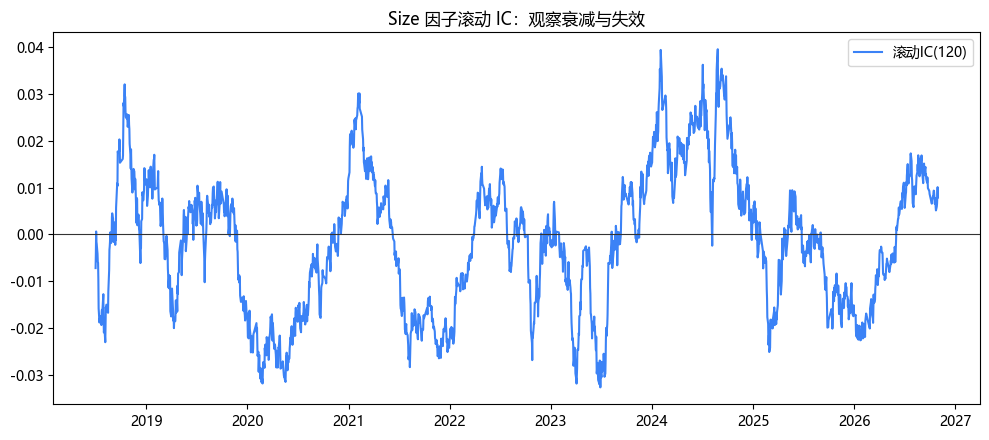

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10,4.5))
ax.plot(ic.index, ic.rolling(120).mean(), label='滚动IC(120)', color='#3b82f6')
ax.axhline(0, color='#333', lw=0.8)
ax.set_title('Size 因子滚动 IC：观察衰减与失效'); ax.legend()
plt.tight_layout(); plt.show()

## 四、拥挤度与估值价差

In [4]:
cs = crowding.crowding_score(size_z, pb, 120)
vs = crowding.value_spread(size_z, pb)
print('拥挤度末值: %.3f（区间0~1）' % cs.dropna().iloc[-1])
print('估值价差末值: %.3f' % vs.dropna().iloc[-1])

拥挤度末值: 0.478（区间0~1）
估值价差末值: 0.291


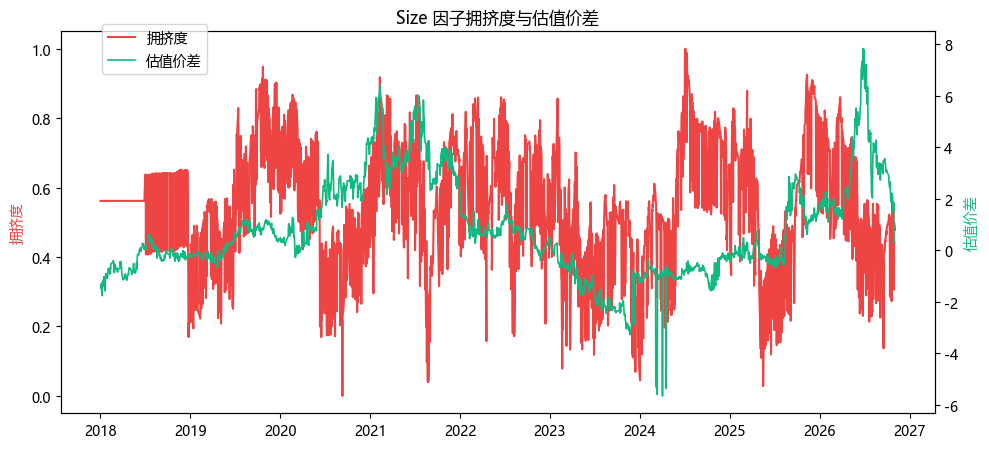

In [5]:
fig, ax1 = plt.subplots(figsize=(10,4.6))
ax1.plot(cs.index, cs, color='#ef4444', label='拥挤度')
ax1.set_ylabel('拥挤度', color='#ef4444')
ax2 = ax1.twinx()
ax2.plot(vs.index, vs, color='#10b981', label='估值价差', lw=1.2)
ax2.set_ylabel('估值价差', color='#10b981')
ax1.set_title('Size 因子拥挤度与估值价差')
fig.legend(loc='upper left', bbox_to_anchor=(0.1,0.95))
plt.tight_layout(); plt.show()

## 五、因子容量：冲击模型

In [6]:
# 给定日均成交额，不同可接受冲击下的可承载金额
adv = 2e8
rows = []
for bps in [5,10,20,30]:
    cap, part = crowding.factor_capacity(adv, max_impact_bps=bps,
                                        daily_vol=0.02)
    rows.append({'可接受冲击bps':bps,'参与率':round(part,4),
                 '容量(万元)':round(cap/1e4,1)})
cap_tbl = pd.DataFrame(rows).set_index('可接受冲击bps')
print(cap_tbl.to_string())

             参与率  容量(万元)
可接受冲击bps                
5         0.0006    12.5
10        0.0025    50.0
20        0.0100   200.0
30        0.0225   450.0


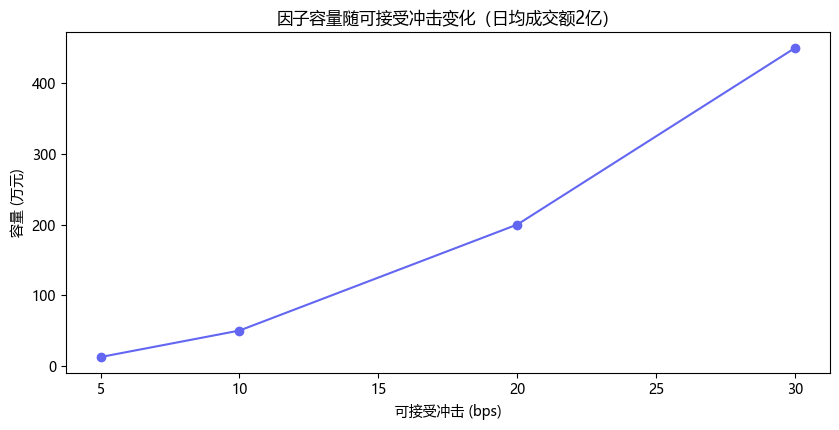

In [7]:
fig, ax = plt.subplots(figsize=(8.5,4.4))
ax.plot(cap_tbl.index, cap_tbl['容量(万元)'], 'o-', color='#6366f1')
ax.set_xlabel('可接受冲击 (bps)'); ax.set_ylabel('容量 (万元)')
ax.set_title('因子容量随可接受冲击变化（日均成交额2亿）')
plt.tight_layout(); plt.show()

## 六、小结与面试要点

- 因子会衰减：用滚动 IC/IR 监控；拥挤时暴露集中、价差收窄，反转风险高。
- 容量由流动性和冲击决定：可接受冲击越大、参与率越高，可承载资金越多。

**面试高频：**
- 怎么判断因子拥挤？（答：暴露集中度、估值价差、近期收益、波动率与相关性综合判断）
- 因子为什么会衰减？（答：资金涌入套利、市场结构变化、交易成本侵蚀）
- 因子容量怎么估？（答：冲击模型，给定可接受冲击反推参与率再乘日均成交额）
- 拥挤因子有什么风险？（答：拥挤后收益变薄、反转时踩踏回撤大）

## 动手练习
1. 画滚动 IC，找出因子明显走弱的时段；
2. 计算拥挤度和估值价差，分析当前是否拥挤；
3. 用不同冲击假设估算容量，理解容量与流动性的关系。

---
下一节 M2.9 进入因子挖掘前沿。